# Lokalny filtr antyphishingowy: TF-IDF znakowe + słowne i liniowy SVM

Kompletny model i skrypty znajdują się w `phishing-detector/src/`. Bez API modeli, bez pobierania
wag i bez połączeń sieciowych podczas predykcji. `1` = phishing, `0` = benign.

Domyślnie notebook korzysta z **dostarczonego wytrenowanego modelu** i ponownie
ocenia 200 dołączonych próbek testowych. Pełny test zapisano po treningu i ponownie sprawdzono po kompresji;
jego raport odczytujemy z pliku, nie przedstawiamy go jako ponownie wykonanego tutaj.
Opcjonalny przełącznik `RETRAIN` uruchamia rzeczywisty trening od początku
(z plikiem wskazanym w DATASET), w osobnym katalogu.

In [1]:
import sys, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents]
           if (p / 'core.py').exists() and (p / 'train.py').exists())
sys.path.insert(0, str(SRC))
from core import load_model, read_records, score_texts, evaluate_model

## 1. Odtworzenie treningu (opcjonalne)

Deduplikacja i podział 60/20/20 (seed=42) są identyczne jak w baseline.
Uczymy dwa TF-IDF na train: znakowe 3–5-gramy (60 000 cech) i słowne 1–2-gramy
(30 000), łączymy je przez FeatureUnion i uczymy LinearSVC C=0,25.
Następnie wybieramy 10 000 cech znakowych i 5000 słownych według wag na train,
ponownie uczymy SVM na train i kwantyzujemy 99,9% wag do siatki 6-bitowej,
zachowując największe wagi dokładnie. Dopiero wtedy kalibrujemy próg.
Próg minimalizuje FPR przy czułości co najmniej 92,8% na walidacji.
Architekturę bazową wybrano spośród ośmiu modeli; kompresję spośród 20 wariantów
na walidacji. Test nie był używany w żadnym wyszukiwaniu.
Raporty porównania znajdują się w `reports/optimization.md` i `validation_candidates.json`.

In [2]:
RETRAIN = False
DATASET = None  # np. Path("/sciezka/dane.csv")
DATA_OPTIONS = {}  # np. {"text_column": "message", "label_column": "target"}
RUN_DIR = SRC
if RETRAIN:
    if DATASET is None:
        raise ValueError('Wskaż DATASET przed włączeniem RETRAIN')
    from train import train_model
    RUN_DIR = SRC / 'experiments' / 'notebook-retrain'
    train_model(data_dir=DATASET, output_dir=RUN_DIR, min_recall=0.928, **DATA_OPTIONS)
MODEL = RUN_DIR / 'models' / 'pipeline.joblib'
metadata = json.loads((MODEL.parent / 'metadata.json').read_text())
bundle = load_model(MODEL)
assert hashlib.sha256(MODEL.read_bytes()).hexdigest() == metadata['model_sha256']
display(pd.DataFrame(metadata['split_info']['splits']).T)
display(pd.DataFrame([{'cechy': metadata['features'], 'próg': metadata['threshold'],
                       'FPR walidacji': metadata['validation']['fpr'],
                       'czułość walidacji': metadata['validation']['recall'],
                       'etap uczenia [s]': metadata['fit_seconds']}]))

,samples,phishing,keys_sha256
train,46051,19168,0735bd8c01ebc825a80d16e23d0b7dbc43df362315edb2...
validation,15350,6389,32675f79a61b75b37fa8e1e7c75548cb65bd9b2009d9c3...
test,15351,6390,dfd8553894d3de6c0fcc0681c01b45bbd69614d391b3bd...


,cechy,próg,FPR walidacji,czułość walidacji,etap uczenia [s]
0,15000,0.101889,0.030577,0.928001,39.893572


## 2. Ścieżka lokalnej predykcji

Normalizacja (limit 4000 znaków, whitespace, lowercase) jest wspólna dla
treningu i inferencji. SVM zwraca margines, **nie skalibrowane prawdopodobieństwo**.
Model jest ładowany raz; cały batch korzysta z tego samego słownika, IDF i progu.

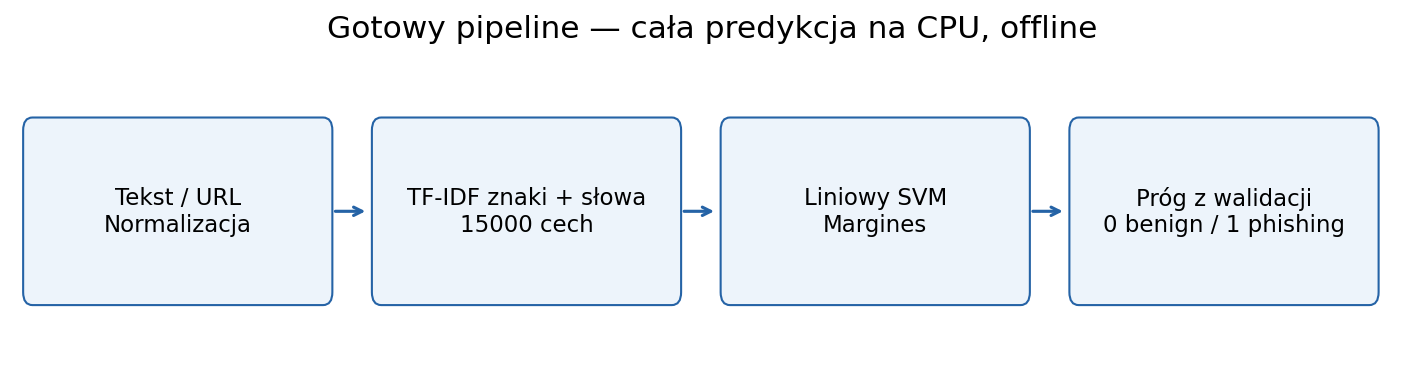

In [3]:
import os, tempfile, io
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'solution-mpl'))
os.environ.setdefault('XDG_CACHE_HOME', str(Path(tempfile.gettempdir()) / 'solution-cache'))
Path(os.environ['XDG_CACHE_HOME']).mkdir(parents=True, exist_ok=True)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.set(xlim=(0, 12), ylim=(0, 2)); ax.axis('off')
steps = ['Tekst / URL\nNormalizacja', f"TF-IDF znaki + słowa\n{metadata['features']} cech",
         'Liniowy SVM\nMargines', 'Próg z walidacji\n0 benign / 1 phishing']
for i, step in enumerate(steps):
    ax.add_patch(FancyBboxPatch((3*i+.15, .5), 2.5, 1, boxstyle='round,pad=0.08',
                                facecolor='#edf4fb', edgecolor='#2563a6'))
    ax.text(3*i+1.4, 1, step, ha='center', va='center', fontsize=11)
    if i<3:
        ax.annotate('', xy=(3*i+3.05, 1), xytext=(3*i+2.72, 1),
                    arrowprops=dict(arrowstyle='->', color='#2563a6', lw=1.5))
ax.set_title('Gotowy pipeline — cała predykcja na CPU, offline', fontsize=15)
def show(fig):
    buffer=io.BytesIO(); fig.savefig(buffer, format='png', dpi=150, bbox_inches='tight')
    display(Image(data=buffer.getvalue(), width=1100)); plt.close(fig)
show(fig)

## 3. Ponowna ocena dołączonych próbek

`examples/test.jsonl` zawiera 200 wejść z odłożonego testu, z etykietami i ID.
To podzbiór tego samego testu, a nie nowy niezależny benchmark. Próbki obejmują
URL/SMS/e-maile/HTML. Nie wyświetlamy ani nie wykonujemy ich zawartości.

In [4]:
records = list(read_records(RUN_DIR / 'examples' / 'test.jsonl', labels=True))
texts = [r['text'] for r in records]
labels = [r['label'] for r in records]
scores = score_texts(bundle, texts)
sample_report = evaluate_model(bundle, texts, labels, MODEL)
recorded_sample = json.loads((RUN_DIR / 'reports' / 'sample_metrics.json').read_text())
assert sample_report['confusion_matrix'] == recorded_sample['confusion_matrix']
display(pd.DataFrame({'id': [r['id'][:12] for r in records[:5]],
                      'etykieta': labels[:5], 'margines': scores[:5],
                      'predykcja': (scores[:5] >= bundle['threshold']).astype(int)}))
display(pd.DataFrame([{'próby': sample_report['samples'],
                       'czułość': sample_report['recall'], 'precision': sample_report['precision'],
                       'F1': sample_report['f1'], 'FPR': sample_report['fpr'],
                       'ms/próbkę': sample_report['timing']['median_ms_per_sample']}]))

,id,etykieta,margines,predykcja
0,03b16b1e815a,1,1.324420,1
1,a5c623f998a5,1,-0.439878,0
2,7e560957c434,0,-1.118589,0
3,3ce69feb2053,0,-1.881090,0
4,90ef18bc5102,0,-1.463627,0


,próby,czułość,precision,F1,FPR,ms/próbkę
0,200,0.891566,0.936709,0.91358,0.042735,0.754617


## 4. Wynik pełnego odłożonego testu i kryteria zadania

Poniżej **zapisany raport pełnego testu** dostarczonego modelu. Rozmiar oznacza rzeczywisty
skompresowany plik joblib. Czas obejmuje normalizację, TF-IDF i SVM dla batcha
512 próbek, mediana pięciu powtórzeń po rozgrzewce; nie obejmuje ładowania pliku
modelu ani danych i nie oznacza opóźnienia pojedynczego żądania.

,próby testowe,model [MiB],mediana ms/próbkę,czułość,FPR,F1
0,15351,0.072973,0.787996,0.926291,0.031358,0.94027


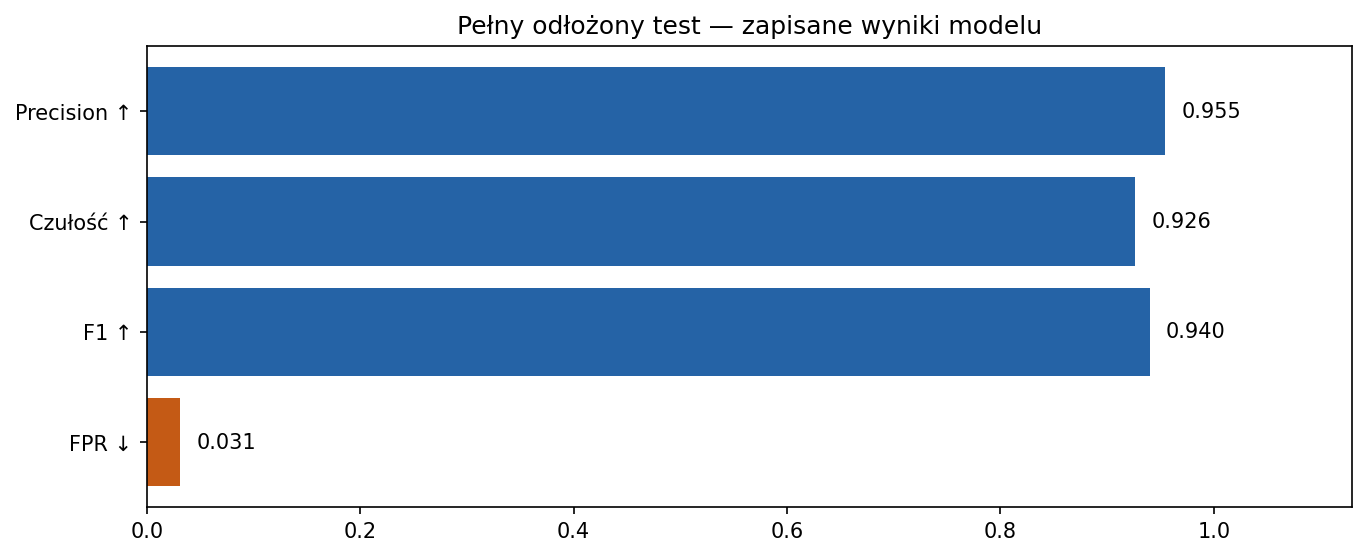

Model: **0.073 MiB**; czułość testowa **92.6%**, FPR **3.1%**. Czułość ≥92,8% była wymaganiem na walidacji, nie gwarancją na nowych danych.

In [5]:
full = json.loads((RUN_DIR / 'reports' / 'test_metrics.json').read_text())
assert full['model_sha256'] == metadata['model_sha256']
assert full['samples'] == metadata['split_info']['splits']['test']['samples']
display(pd.DataFrame([{'próby testowe': full['samples'], 'model [MiB]': full['model_mib'],
                       'mediana ms/próbkę': full['timing']['median_ms_per_sample'],
                       'czułość': full['recall'], 'FPR': full['fpr'], 'F1': full['f1']}]))
fig, ax = plt.subplots(figsize=(9, 3.6), layout='constrained')
keys = ['precision', 'recall', 'f1', 'fpr']
values = [full[k] for k in keys]
ax.barh(['Precision ↑', 'Czułość ↑', 'F1 ↑', 'FPR ↓'], values,
        color=['#2563a6']*3+['#c45a15'])
ax.invert_yaxis(); ax.set_xlim(0, 1.13)
ax.set_title('Pełny odłożony test — zapisane wyniki modelu')
for i, value in enumerate(values): ax.text(value+.015, i, f'{value:.3f}', va='center')
show(fig)
display(Markdown(f"Model: **{full['model_mib']:.3f} MiB**; czułość testowa "
                 f"**{full['recall']:.1%}**, FPR **{full['fpr']:.1%}**. "
                 f"Czułość ≥92,8% była wymaganiem na walidacji, nie gwarancją na nowych danych."))

## 5. Historyczne porównanie z pierwotnym modelem

Poniżej historyczne wyniki przed kompresją. Rozmiar 1,525 MiB dotyczy poprzedniego zapisu modelu.
Poprawę FPR i czułości uzyskano kosztem większego modelu i czasu predykcji.
Ten test był używany we wcześniejszych pracach: potrzebna jest jeszcze niezależna walidacja czasowa.

,wersja,FPR,czułość,F1,FP,model [MiB],ms/próbkę
0,before,0.050887,0.921440,0.924768,456,0.328513,0.920802
1,after,0.029573,0.924883,0.940708,265,1.525320,1.272766


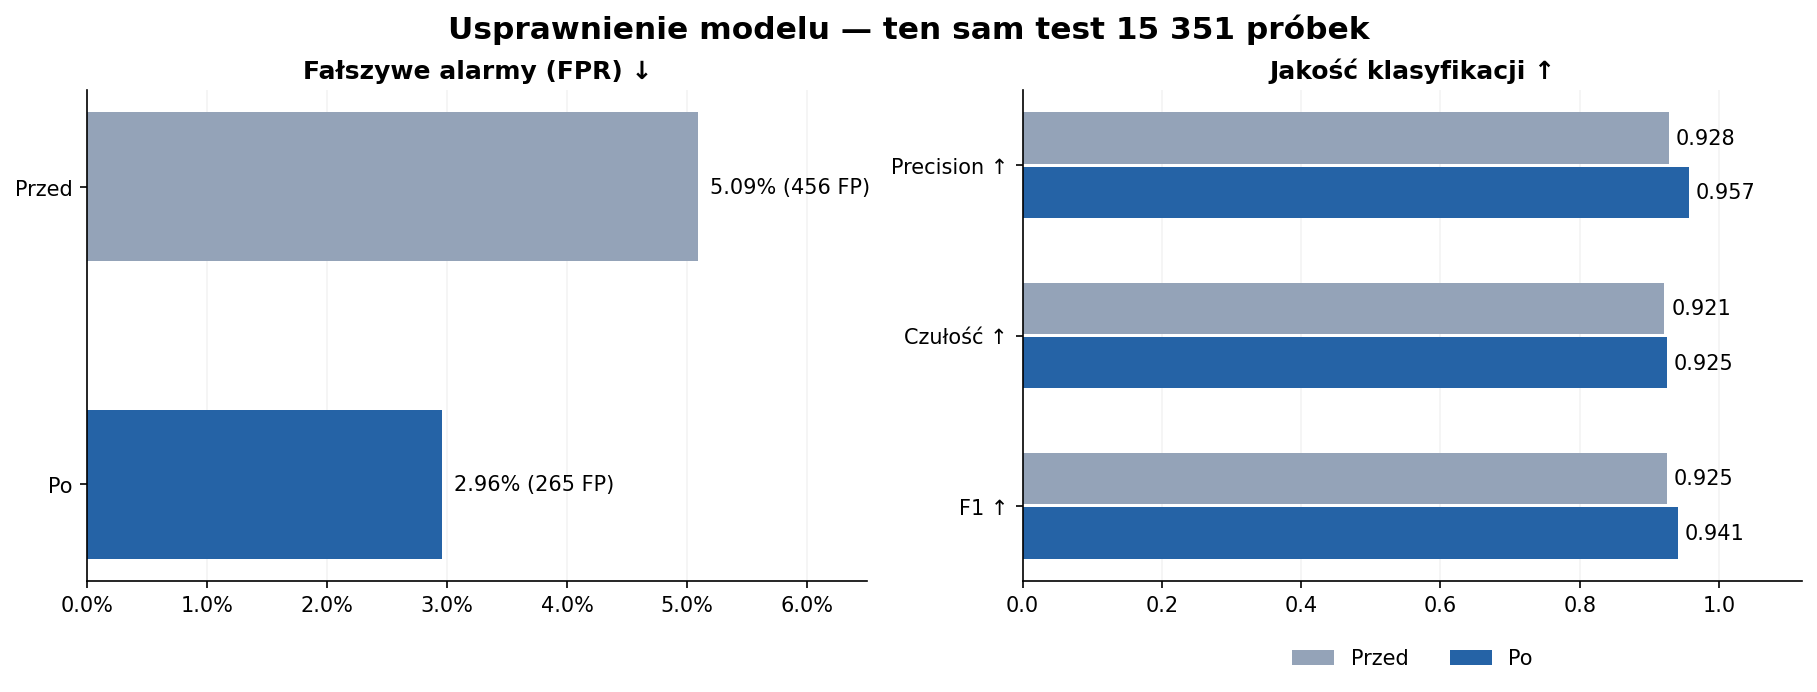

In [6]:
comparison_path = RUN_DIR / 'reports' / 'optimization.json'
if comparison_path.exists():
    comparison = json.loads(comparison_path.read_text())
    comparison_rows = []
    for stage in ['before', 'after']:
        report = comparison[stage]
        comparison_rows.append({'wersja': stage, 'FPR': report['fpr'], 'czułość': report['recall'],
                                'F1': report['f1'], 'FP': report['confusion_matrix']['fp'],
                                'model [MiB]': report['model_mib'],
                                'ms/próbkę': report['timing']['median_ms_per_sample']})
    display(pd.DataFrame(comparison_rows))
    display(Image(filename=str(RUN_DIR / 'reports' / 'optimization.png'), width=1100))
else:
    print('Osobny retrening: porównanie z baseline nie zostało wykonane w tym katalogu.')

## 6. Historyczny pierwszy etap kompresji
W pierwszym, historycznym etapie zachowano wszystkie 90 000 cech, IDF, konfigurację i próg (1,525 → 0,681 MiB). Indeksy słowników zapisano jako posortowane Python int, wagi SVM jako float32, a joblib skompresowano LZMA (6). Float32 powoduje niewielkie zaokrąglenia; ich wpływ sprawdzono na oryginalnej walidacji i teście. Obecny model opisany poniżej dodatkowo ogranicza liczbę cech i kwantyzuje wagi.


In [7]:
size_path = RUN_DIR / 'reports' / 'size_optimization.json'
if size_path.exists():
    size_report = json.loads(size_path.read_text())
    display(pd.DataFrame([{'wersja': stage, 'MiB': size_report[stage]['model_mib'],
                           'ms/próbkę': size_report[stage]['timing']['median_ms_per_sample'],
                           'ładowanie [ms]': size_report[stage]['load_median_ms'],
                           'czułość': size_report[stage]['recall'], 'FPR': size_report[stage]['fpr']}
                          for stage in ['before', 'after']]))
    print('Historyczny pierwszy etap — zmienione predykcje:', size_report['test']['changed_predictions'])


,wersja,MiB,ms/próbkę,ładowanie [ms],czułość,FPR
0,before,1.525320,1.134423,306.486993,0.924883,0.029573
1,after,0.681074,1.059674,146.517545,0.924883,0.029573


Historyczny pierwszy etap — zmienione predykcje: 0


## 7. Bieżąca kompresja: selekcja cech i kwantyzacja
Z 90 tys. cech pozostawiono 15 tys. i ponownie nauczono SVM na train. Siatka 6-bitowa obejmuje 99,9% wag; 15 skrajnych wag zachowano dokładnie. Wagi podczas inferencji pozostają float32. Słowniki zapisano jako sekwencje i zastosowano LZMA.
Na walidacji porównano 20 wariantów, przy limitach spadku recall 0,5 p.p. i wzrostu FPR 0,3 p.p. Po wyborze najmniejszego wariantu przywrócono pierwotne minimum recall 92,8% i sprawdzono limit FPR na walidacji. Konfigurację zamrożono przed testem. Poniżej zapisany raport porównania na 15 351 próbkach, nie nowy niezależny benchmark.


In [8]:
compression_path = RUN_DIR / 'reports' / 'compression_comparison.json'
if compression_path.exists():
    compression = json.loads(compression_path.read_text())
    assert compression['after']['model_sha256'] == metadata['model_sha256']
    display(pd.DataFrame([{'wersja': stage, 'MiB': compression[stage]['model_mib'],
                           'czułość': compression[stage]['recall'], 'FPR': compression[stage]['fpr'],
                           'F1': compression[stage]['f1'],
                           'ms/próbkę': compression[stage]['timing']['median_ms_per_sample'],
                           'ładowanie [ms]': compression[stage]['load_median_ms']}
                          for stage in ['before', 'after']]))
    display(Markdown(f"Zmniejszenie: **{compression['reduction_percent']:.2f}%**; "
                     f"FPR: **{compression['fpr_change_pp']:+.2f} p.p.**; "
                     f"czułość: **{compression['recall_change_pp']:+.2f} p.p.**."))
    display(pd.DataFrame(compression['search']['rows'])[['name', 'model_bytes', 'recall', 'fpr', 'eligible']])
else:
    print('Osobny retrening: użyj raportu pełnego testu powyżej.')


,wersja,MiB,czułość,FPR,F1,ms/próbkę,ładowanie [ms]
0,before,0.681074,0.924883,0.029573,0.940708,0.891898,127.250216
1,after,0.072973,0.926291,0.031358,0.940270,0.787996,13.542837


Zmniejszenie: **89.29%**; FPR: **+0.18 p.p.**; czułość: **+0.14 p.p.**.

,name,model_bytes,recall,fpr,eligible
0,char60000-word30000-q32,656693,0.924088,0.027564,True
1,char60000-word30000-q10,442244,0.924088,0.027564,True
2,char60000-word30000-q8,415418,0.923932,0.027675,True
3,char60000-word30000-q6,389465,0.924401,0.028010,True
4,char40000-word20000-q32,442185,0.923932,0.026671,True
5,char40000-word20000-q10,303301,0.924558,0.026783,True
6,char40000-word20000-q8,284615,0.924558,0.026671,True
7,char40000-word20000-q6,266920,0.923932,0.026560,True
8,char30000-word15000-q32,337022,0.924088,0.026560,True
9,char30000-word15000-q10,233514,0.924401,0.026560,True


## Podsumowanie i ograniczenia

- Gotowy model, próg, skrypty i przykłady pozwalają na lokalną inferencję bez pełnego datasetu.
- `predict.py` obsługuje pojedynczy tekst i batch JSONL/CSV; `evaluate.py` raportuje
  czułość, błędy, rozmiar i czas. `README.md` zawiera dokładne komendy.
- Limit długości może usuwać istotną końcówkę wiadomości. Zbiór miesza typy danych,
  a brak czasu i ID kampanii uniemożliwia wiarygodny test Zero-Day.
- Usunięto identyczne znormalizowane wejścia i konflikty etykiet, lecz bliskie
  duplikaty i wspólne domeny/kampanie nadal mogą zawyżać wynik losowego podziału.
- Ocena pakietu używa pełnego testu odłożonego przed treningiem; próbki dołączone
  do pakietu nie powinny służyć do dostrajania po ocenie. Test był już używany
  do porównań badawczych w repozytorium; do końcowego wdrożenia potrzebny jest
  nowy, niezależny zbiór oraz próg zgodny z kosztem fałszywych alarmów.